<a href="https://colab.research.google.com/github/profrash-tech/biometrics-hub-notebooks/blob/main/NB3_Feature_Engineering_and_Statistical_Modelling_STUDENT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 3 · Feature Engineering and Statistical Modelling

**About 330 minutes** · Course: *Data Science and Machine Learning with a Framingham teaching dataset*

*Prerequisites: Notebooks 1 and 2. Models here are fitted on the training split only; the test set stays sealed until the final evaluations in Notebooks 4 and 5.*

### 🎯 Learning objectives
After this notebook you will be able to:
- define the regression target and the classification target and keep them apart
- explain proxies and leakage and choose predictors accordingly
- create a train/validation/test split first and fit every data-dependent step on training rows only
- fill gaps with the training median and add a missingness indicator
- create interpretable features with fixed constants
- detect overlapping predictors with VIF
- fit and read a linear regression and a logistic regression (coefficients, intervals, odds ratios)
- check assumptions with residual plots and tests, and respond to violations
- distinguish statistical from practical importance

### ❓ Research questions addressed here
- **RQ7.** Is age associated with systolic blood pressure? (adjusted view)
- **RQ8.** Are smoking status and CHD status statistically associated? (adjusted view)
- **RQ10.** Can systolic blood pressure be estimated from selected demographic and clinical predictors? (statistical model)
- **RQ11.** Which predictors contribute most to explaining variation in systolic blood pressure? (first look)
- **RQ13.** Can the available variables distinguish observations with and without recorded ten-year CHD? (explanatory logistic model)

### 🧭 How to use this notebook
- Run cells from **top to bottom** with **Shift + Enter**. Do not skip cells.
- Each new idea gets its own short cell: **first** a plain-language explanation, **then** the code, **then** a
  line-by-line walk-through of what each line does. Read all three before moving on.
- Every part follows the same seven-step rhythm:
  **📘 LEARN** (idea) → **▶️ SEE** (worked code) → **✏️ TRY** (you code) → **🔍 ANALYZE** (inspect results) →
  **💬 INTERPRET** (connect to the research question) → **✅ CHECK** (test yourself) → **🔬 RESEARCH** (go further).
- Cells marked `# TODO` are for you. Replace the placeholder (`None`) with your own code.
  Unfinished cells still run, so the notebook never stops because of a blank.
- Written answers go between the triple quotes of the `answer_...` variable. Knowledge-check answers are a
  single letter.
- After each exercise there is a one-line **🎯 check** cell. Run it to see ✅ or ❌ and a hint. It never shows
  the answer and never stops the notebook. The **📊 progress** cell near the end adds everything up.
- Exercises are self-contained: they use only objects created in the guided cells above them, never your own
  answers from other exercises.
- Solutions are **not** in this notebook. Your instructor decides when to release them.

**🎯 Course checker.** Click ▶ once on the next cell. It loads the small helper that tells you whether each exercise is right (✅ or ❌) and keeps a progress count. There is nothing to read or change in it. If you are offline, the notebook still works; only the feedback is unavailable.

In [394]:
#@title ⚙️ Course checker: click ▶ once, nothing to read here { display-mode: "form" }
import os, urllib.request
CHECKER_URL = "https://raw.githubusercontent.com/festusoladayoonline-debug/biometrics-hub-checker/main/hub_check.py"
try:                                    # get the newest checker; use the local copy if offline
    _data = urllib.request.urlopen(CHECKER_URL, timeout=10).read()
    open("hub_check.py", "wb").write(_data)
except Exception:
    pass
try:
    from hub_check import check, progress
    print("Course checker ready.")
except Exception:                       # the notebook still works without feedback
    def check(ex): print("Checker not available (offline?). Your notebook still works; ask your teacher.")
    def progress(n=None): print("Checker not available.")
    print("Course checker could not be loaded.")

Course checker ready.


### ⚠️ Read this before analysing anything
- The data file is a **commonly circulated teaching subset** associated with the Framingham Heart Study. It is
  **not** the complete original cohort and not an official, representative clinical dataset. Its provenance and
  sampling are not documented in the file.
- The data are **observational**. Associations found here do **not** establish causation.
- Missing values and a rare outcome (about 15% recorded CHD) affect every analysis you will do.
- Any prediction exercise is **educational**. It is not a clinically validated risk tool, and nothing here is
  individual medical advice.

### ⚙️ Setup
Run the next two cells. The first brings in the tools (called *libraries*) and fixes the random seed so your results can be reproduced; the second finds and loads the data **without changing it**.

### ▶️ SEE · Load the tools

The first cell loads the libraries this notebook uses.

In [395]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf

SEED = 42                      # one fixed seed for the whole course
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", 30)
print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 2.2.3 | numpy 2.4.6


**🔎 What each line does**

- `import numpy as np`  →  loads NumPy, the library for fast number arrays, and gives it the short name `np`
- `import pandas as pd`  →  loads pandas, the library for data tables (called DataFrames), short name `pd`
- `import matplotlib.pyplot as plt`  →  loads Matplotlib's plotting tools, short name `plt`
- `import seaborn as sns`  →  loads seaborn, which draws nicer statistical charts on top of Matplotlib
- `SEED = 42`  →  stores the number 42 in a variable called SEED; every random step in the course uses it, so results repeat exactly
- `np.random.seed(SEED)`  →  tells NumPy's random-number generator to start from that seed
- `sns.set_theme`  →  chooses a clean chart style for every figure
- `pd.set_option("display.precision", 3)`  →  shows numbers with 3 decimals when pandas prints a table
- `pd.set_option("display.max_columns", 30)`  →  lets pandas show up to 30 columns instead of hiding some
- `print("pandas"`  →  prints the library versions so you can tell someone exactly what you used
- `from scipy import stats`  →  SciPy statistics tools
- `import statsmodels.api as sm`  →  statsmodels: statistical models
- `import statsmodels.formula.api as smf`  →  lets us write models as text formulas such as 'sysBP ~ age'

**👀 What you should see:** one line such as `pandas 2.x | numpy 1.x` and no error message.

### ▶️ SEE · Load the data

The second cell finds the data file and reads it into a table.

In [396]:
from pathlib import Path

CANDIDATES = [Path("data/framingham.csv"), Path("../data/framingham.csv"), Path("framingham.csv")]
DATA_PATH = next((p for p in CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    try:                                   # Google Colab: upload the file when asked
        from google.colab import files
        files.upload()
        DATA_PATH = Path("framingham.csv")
    except ImportError:
        raise FileNotFoundError("Put framingham.csv in a folder called data/ next to the notebooks.")

df_raw = pd.read_csv(DATA_PATH)            # "NA" text in the file becomes NaN
df = df_raw.copy()                         # work on a copy; df_raw stays untouched
print("Loaded", DATA_PATH, "->", df.shape[0], "rows x", df.shape[1], "columns")

Loaded framingham.csv -> 4240 rows x 16 columns


**🔎 What each line does**

- `from pathlib import Path`  →  brings in a tool for working with file locations
- `CANDIDATES = [`  →  a list of places where the data file might be; the code tries them in order
- `DATA_PATH = next(`  →  picks the first location where the file really exists (or `None` if it is nowhere)
- `if DATA_PATH is None:`  →  only if the file was not found, try the Google Colab upload instead
- `files.upload()`  →  in Colab this opens a window to upload framingham.csv
- `raise FileNotFoundError`  →  stops with a clear message if the file cannot be found anywhere
- `df_raw = pd.read_csv(DATA_PATH)`  →  reads the CSV file into a pandas table called `df_raw`; the text NA becomes a missing value (NaN)
- `df = df_raw.copy()`  →  makes a separate working copy called `df`, so the untouched original is always there
- `print("Loaded"`  →  prints how many rows and columns were loaded: expect 4240 rows x 16 columns

**👀 What you should see:** `Loaded data/framingham.csv -> 4240 rows x 16 columns`.

### ▶️ SEE · More tools for modelling

Five more imports for this notebook. Each one is a single ready-made tool.

In [397]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.metrics import r2_score, mean_squared_error
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
print('modelling tools ready')

modelling tools ready


**🔎 What each line does**

- `train_test_split`  →  scikit-learn's tool for splitting rows into parts
- `SimpleImputer`  →  fills missing values with a learned typical value
- `r2_score, mean_squared_error`  →  ways to score predictions
- `variance_inflation_factor`  →  calculates VIF (overlap between predictors)
- `het_breuschpagan`  →  a test for unequal spread of residuals
- `print('modelling`  →  confirms the cell ran

**👀 What you should see:** `modelling tools ready`.

---
## Part 1 · Two targets, many predictors
*About 20 min · Research question(s): RQ10, RQ13*

### 📘 LEARN · Targets, predictors, proxies and leakage

A **target** (or outcome) is the thing we want to explain or predict; **predictors** are the other columns we use. This course has two targets:

| | Regression target | Classification target |
|---|---|---|
| Outcome | `sysBP` (mmHg, a number) | `TenYearCHD` (0/1; **positive class = 1**) |
| Model here | multiple linear regression | logistic regression |

- A **proxy** is a variable that is almost another measurement of the target (`diaBP` for `sysBP`).
- **Leakage** means the model sees information it would not have in real use, or information partly built from the outcome. A leaky model looks excellent and is useless.
- **Temporal availability**: *when* was each variable recorded relative to the outcome? This file does not say, so every claim is an assumption.

**📖 New words**

- **target**: the outcome we explain or predict
- **predictor**: a column used to explain the target
- **proxy**: a stand-in that nearly repeats the target
- **leakage**: information the model should not have
- **regression**: predicting a number
- **classification**: predicting a category (here yes/no)

### ▶️ SEE · The list of sysBP predictors

We store the predictor names in a list and the excluded ones in a dictionary with the reason for each. A dictionary pairs a name (key) with a reason (value).

In [398]:
SBP_PREDICTORS = ["male", "age", "education", "currentSmoker", "cigsPerDay", "diabetes",
                  "prevalentStroke", "totChol", "BMI", "heartRate", "glucose"]
SBP_EXCLUDED = {
    "diaBP": "another measurement of the same blood pressure (proxy)",
    "prevalentHyp": "may be defined from blood-pressure readings or treatment",
    "TenYearCHD": "an outcome recorded later",
    "BPMeds": "only in a labelled sensitivity analysis (confounding by indication)",
}

**🔎 What each line does**

- `SBP_PREDICTORS = [`  →  the 11 columns allowed as predictors of sysBP
- `SBP_EXCLUDED = {`  →  starts a dictionary of excluded columns
- `"diaBP":`  →  excluded because it nearly repeats the target
- `"prevalentHyp":`  →  excluded because its definition may use blood pressure
- `"TenYearCHD":`  →  excluded because it is recorded later
- `"BPMeds":`  →  kept out of the main model; used only in a clearly labelled extra analysis

**👀 What you should see:** nothing printed; the lists are stored.

### ▶️ SEE · Print the reasons

A `for` loop over a dictionary gives each key and value in turn.

In [399]:
for name, reason in SBP_EXCLUDED.items():
    print("-", name + ":", reason)

- diaBP: another measurement of the same blood pressure (proxy)
- prevalentHyp: may be defined from blood-pressure readings or treatment
- TenYearCHD: an outcome recorded later
- BPMeds: only in a labelled sensitivity analysis (confounding by indication)


**👀 What you should see:** four lines, one per excluded column.

### 🔍 ANALYZE · Question 3.1 · Why exclude diaBP and prevalentHyp for sysBP?

Complete: 'diaBP and prevalentHyp are excluded from the sysBP model because ..., but they can be candidates for the CHD model because ...'. Name one timing or leakage worry that remains for the CHD model.

*Write your answer inside the quotes below (2–5 sentences). Your instructor reads it.*

In [400]:
# [Question 3.1]
answer_3_1 = """`diaBP` and `prevalentHyp` are excluded from the sysBP model because they are closely related to systolic blood pressure and may act as proxy variables, potentially making the model's predictive performance misleading. However, they can be candidates for the CHD model because diastolic blood pressure and a history of hypertension may provide useful information about a patient's risk of developing coronary heart disease. One remaining concern is temporal leakage: we must establish whether these variables were recorded before or at the time of CHD prediction, rather than after the CHD diagnosis.

"""

In [401]:
check("Q3.1")   # 🎯 run this cell to check your answer

📝 answer saved (90 words). Your teacher will read it.


### ✅ CHECK · Knowledge check 3.1

What is a proxy variable?

- **A.** A variable that nearly repeats the target
- **B.** A variable with no missing values
- **C.** The random seed
- **D.** A variable with p < 0.05

In [402]:
# [Knowledge check 3.1]
kc_3_1 = "A"   # type "A", "B", "C" or "D"

In [403]:
check("K3.1")   # 🎯 run this cell to check your answer

✅ `kc_3_1`: correct!


---
## Part 2 · Split first: train, validation and test
*About 30 min · Research question(s): RQ10, RQ13*

### 📘 LEARN · Why the order matters

Before any step that learns from data (filling gaps, scaling, fitting a model), we split the rows into three parts:
- **Training (70%)**: the model and every preprocessing step learn from these rows.
- **Validation (15%)**: used for decisions such as comparing models.
- **Test (15%)**: *sealed* until the very end, so the final score is honest.

If, say, the median used to fill gaps is calculated on the whole file, information from the test rows leaks into training. The **stratified** split keeps about 15% CHD in every part, and **seed 42** makes it repeatable.

**📖 New words**

- **training set**: rows the model learns from
- **validation set**: rows used to compare and tune
- **test set**: rows kept sealed for the final check
- **stratified**: each part keeps the same share of CHD
- **seed**: a fixed starting number so random steps repeat

### ▶️ SEE · Imports for splitting and models

These libraries were loaded in the setup; here is what each does.

In [404]:
print(train_test_split.__name__, "|", SimpleImputer.__name__)

train_test_split | SimpleImputer


**👀 What you should see:** `train_test_split | SimpleImputer`.

### ▶️ SEE · Step 1: cut off the test set

We first remove 15% of the rows as the test set.

In [405]:
train_val, test = train_test_split(df, test_size=0.15,
                                   stratify=df["TenYearCHD"], random_state=SEED)
print(len(train_val), len(test))

3604 636


**🔎 What each line does**

- `train_test_split(df, test_size=0.15`  →  randomly sets 15% of the rows aside
- `stratify=df["TenYearCHD"]`  →  keeps the CHD share the same in both parts
- `random_state=SEED`  →  uses seed 42 so the split is the same every time
- `train_val, test =`  →  two outputs: the remaining 85% and the 15% test set

**👀 What you should see:** `3604 636`.

### ▶️ SEE · Step 2: split the rest into training and validation

From the 85% we take 15 / 85 as validation, so validation is 15% of the whole file.

In [406]:
train, val = train_test_split(train_val, test_size=0.15 / 0.85,
                              stratify=train_val["TenYearCHD"], random_state=SEED)
print(len(train), len(val), len(test))

2968 636 636


**🔎 What each line does**

- `test_size=0.15 / 0.85`  →  15% of the whole file equals 0.15/0.85 of what is left
- `stratify=train_val["TenYearCHD"]`  →  again keep the CHD share equal
- `train, val =`  →  the 70% training rows and the 15% validation rows

**👀 What you should see:** `2968 636 636`.

### ▶️ SEE · Check the CHD share in each part

A loop prints one line per part.

In [407]:
for name, part in [("train", train), ("validation", val), ("test", test)]:
    print(name, len(part), round(part["TenYearCHD"].mean(), 4))

train 2968 0.1516
validation 636 0.1525
test 636 0.1525


**👀 What you should see:** three CHD shares, all about 0.15.

From now on this notebook **looks at and fits on `train` only**. `val` is used for one honest check and `test` is never opened here.

### ✏️ TRY · Exercise 3.1 · Audit the split

Store the CHD share of each part in `prev_train`, `prev_val`, `prev_test`. Then store in `n_overlap` the number of row labels shared between `train` and `val` (use `set(train.index) & set(val.index)`; a correct split gives 0).

**Result variable(s):** `prev_train`, `prev_val`, `prev_test`, `n_overlap`

In [408]:
# [Exercise 3.1]
prev_train = train["TenYearCHD"].mean()     # train["TenYearCHD"].mean()
prev_val = val["TenYearCHD"].mean()       # val["TenYearCHD"].mean()
prev_test = test["TenYearCHD"].mean()      # test["TenYearCHD"].mean()
n_overlap = len(set(train.index) & set(val.index))     # len(set(train.index) & set(val.index))
print(prev_train, prev_val, prev_test, n_overlap)

0.15161725067385445 0.15251572327044025 0.15251572327044025 0


In [409]:
check("3.1")   # 🎯 run this cell to check your answer

✅ `prev_train`: correct!
✅ `prev_val`: correct!
✅ `prev_test`: correct!
✅ `n_overlap`: correct!


### 💬 INTERPRET · Question 3.2 · What would leak?

A classmate fills missing glucose with the median of the **whole** file and *then* splits the data. What goes wrong? Start: 'The test rows influence ... because ...'.

*Write your answer inside the quotes below (2–5 sentences). Your instructor reads it.*

In [410]:
# [Question 3.2]
answer_3_2 = """The test rows influence the calculation of the median because missing glucose values are filled using information from the entire dataset before splitting it into training and testing sets. This causes data leakage because information from the test set enters the training process, potentially producing overly optimistic model performance. The correct approach is to split the data first, calculate the median using only the training data, and use that same median to impute missing values in both datasets.

"""

In [411]:
check("Q3.2")   # 🎯 run this cell to check your answer

📝 answer saved (78 words). Your teacher will read it.


### ✅ CHECK · Knowledge check 3.2

Which step is **allowed** before splitting?

- **A.** Computing the median of each column to fill gaps
- **B.** Fitting a scaler
- **C.** Choosing the random seed and the split proportions
- **D.** Selecting features by their correlation with the outcome

In [412]:
# [Knowledge check 3.2]
kc_3_2 = "C"   # type "A", "B", "C" or "D"

In [413]:
check("K3.2")   # 🎯 run this cell to check your answer

✅ `kc_3_2`: correct!


---
## Part 3 · Missing data: filling gaps without leakage
*About 30 min · Research question(s): RQ10*

### 📘 LEARN · Options and their costs

| Strategy | Idea | Main risk |
|---|---|---|
| Complete-case | drop rows with any gap | fewer rows; bias if gaps relate to the outcome |
| Single imputation | fill with a typical training value (median / most frequent) | shrinks variability |
| Imputation + indicator | also record *where* the value was missing | one extra column |

Rules here: never fill with **0**, and **fit the imputer on training rows only**, then *apply* it to validation and test.

**📖 New words**

- **imputation**: filling a missing value with a sensible value
- **median**: the middle value
- **indicator**: a 0/1 column saying 'this value was missing'
- **fit**: let a tool learn something from the data (here: the median)
- **transform**: apply what was learned to rows

### ▶️ SEE · Step 1: the median of one column, from training

This is what an imputer will learn for glucose.

In [414]:
print(train["glucose"].median())

78.0


**👀 What you should see:** `78.0`.

### ▶️ SEE · Step 2: define the column groups

Numeric columns get the median; yes/no and category columns get the most frequent value.

In [415]:
num_cols = ["age", "cigsPerDay", "totChol", "sysBP", "diaBP", "BMI", "heartRate", "glucose"]
cat_cols = ["male", "education", "currentSmoker", "BPMeds", "prevalentStroke", "prevalentHyp", "diabetes"]

**👀 What you should see:** nothing printed.

### ▶️ SEE · Step 3: fit the imputers on the training rows only

`.fit(...)` learns the medians (or most frequent values) from `train`.

In [416]:
imp_num = SimpleImputer(strategy="median").fit(train[num_cols])
imp_cat = SimpleImputer(strategy="most_frequent").fit(train[cat_cols])
print(dict(zip(num_cols, imp_num.statistics_))["glucose"])

78.0


**👀 What you should see:** `78.0`, the same median as before.

### ▶️ SEE · Step 4: one function that applies the imputers

A function lets us apply the same recipe to train, validation (and later test) without copy-pasting.

In [417]:
def impute(frame):
    out = frame.copy()
    out["glucose_missing"] = frame["glucose"].isna().astype(int)
    out[num_cols] = imp_num.transform(frame[num_cols])
    out[cat_cols] = imp_cat.transform(frame[cat_cols])
    return out

**🔎 What each line does**

- `def impute(frame):`  →  defines a function that takes any table of rows
- `out = frame.copy()`  →  works on a copy so the original is untouched
- `out["glucose_missing"] = `  →  adds the indicator column: 1 where glucose was missing, 0 otherwise (`.isna()` finds gaps, `.astype(int)` turns True/False into 1/0)
- `out[num_cols] = imp_num.transform`  →  fills numeric gaps with the training medians
- `out[cat_cols] = imp_cat.transform`  →  fills category gaps with the training most-frequent values
- `return out`  →  gives back the completed table

**👀 What you should see:** nothing printed; the function is defined.

### ▶️ SEE · Step 5: apply to train and validation

Notice that both use the numbers learned from `train`.

In [418]:
train_imp, val_imp = impute(train), impute(val)
print(len(train), len(train.dropna()), int(train_imp[num_cols + cat_cols].isna().any(axis=1).sum()))

2968 2528 0


**👀 What you should see:** 2968 training rows, only about 2.5 thousand complete cases, and 0 rows with gaps after imputation.

### ✏️ TRY · Exercise 3.2 · Training statistics are not whole-file statistics

Store `n_missing_glucose_train` (missing glucose values in `train`), `bmi_mean_train` (mean BMI in `train`), `bmi_mean_all` (mean BMI in all of `df`) and `bmi_mean_gap` (train minus all).

**Result variable(s):** `n_missing_glucose_train`, `bmi_mean_train`, `bmi_mean_all`, `bmi_mean_gap`

In [419]:
# [Exercise 3.2]
n_missing_glucose_train = int(train["glucose"].isna().sum())   # int(train["glucose"].isna().sum())
bmi_mean_train = train["BMI"].mean()            # train["BMI"].mean()
bmi_mean_all = df["BMI"].mean()                   # df["BMI"].mean()
bmi_mean_gap = bmi_mean_train- bmi_mean_all            # bmi_mean_train - bmi_mean_all
print(n_missing_glucose_train, bmi_mean_train, bmi_mean_all, bmi_mean_gap)

296 25.800711864406782 25.80080075811419 -8.889370740661207e-05


In [420]:
check("3.2")   # 🎯 run this cell to check your answer

✅ `n_missing_glucose_train`: correct!
✅ `bmi_mean_train`: correct!
✅ `bmi_mean_all`: correct!
✅ `bmi_mean_gap`: correct!


### 💬 INTERPRET · Question 3.3 · Why add a missing-glucose indicator?

We fill glucose with the training median *and* add `glucose_missing`. What does the indicator allow the model to do, and what could go wrong with only the median?

*Write your answer inside the quotes below (2–5 sentences). Your instructor reads it.*

In [421]:
# [Question 3.3]
answer_3_3 = """The glucose_missing indicator allows the model to distinguish between patients whose glucose values were actually measured and those whose values were missing. This is useful because missingness itself may contain information, such as differences in clinical testing practices or patient characteristics.

If we use only median imputation, the model may treat an imputed glucose value as though it were an actual measurement. This can hide potentially meaningful missing-data patterns and introduce bias if the reasons for missingness are related to the patient's health status.

"""

In [422]:
check("Q3.3")   # 🎯 run this cell to check your answer

📝 answer saved (84 words). Your teacher will read it.


### ✅ CHECK · Knowledge check 3.3

Why is replacing missing glucose with **0** a poor default?

- **A.** It is slower
- **B.** Zero is an impossible glucose value and distorts the mean and the model
- **C.** It always improves accuracy
- **D.** pandas does not allow it

In [423]:
# [Knowledge check 3.3]
kc_3_3 = "B"   # type "A", "B", "C" or "D"

In [424]:
check("K3.3")   # 🎯 run this cell to check your answer

✅ `kc_3_3`: correct!


---
## Part 4 · Making interpretable features
*About 25 min · Research question(s): RQ10*

### 📘 LEARN · Centre and rescale with fixed constants

A coefficient 'per one year' or 'per one mg/dL' is hard to read. We re-express each variable in meaningful steps, centred on a round reference value:

| New feature | Definition | One unit means |
|---|---|---|
| `age_dec` | (age - 50) / 10 | 10 years older |
| `bmi_5` | (BMI - 25) / 5 | 5 BMI units higher |
| `chol_40` | (totChol - 240) / 40 | 40 mg/dL higher |
| `hr_10` | (heartRate - 75) / 10 | 10 bpm faster |
| `glu_20` | (glucose - 80) / 20 | 20 mg/dL higher |
| `cigs_10` | cigsPerDay / 10 | 10 more cigarettes a day |
| `sbp_20` | (sysBP - 130) / 20 | 20 mmHg higher (CHD model only) |

The constants are **fixed by us, not learned from data**, so there is no leakage. Education is a **category** (1-4), not a number, because the gaps between levels are not equal.

### ▶️ SEE · One feature by hand

Subtract 50, divide by 10: a 60-year-old gets 1.0.

In [425]:
example = train_imp[["age"]].head(3).copy()
example["age_dec"] = (example["age"] - 50) / 10
print(example)

       age  age_dec
1558  61.0      1.1
3207  52.0      0.2
1955  42.0     -0.8


**👀 What you should see:** ages and their `age_dec` values (for example 60 becomes 1.0).

### ▶️ SEE · All features in one function

The same recipe for each variable, packed in a function so it can be applied to any imputed table.

In [426]:
def engineer(frame):
    out = frame.copy()
    out["age_dec"] = (out["age"] - 50) / 10
    out["bmi_5"] = (out["BMI"] - 25) / 5
    out["chol_40"] = (out["totChol"] - 240) / 40
    out["hr_10"] = (out["heartRate"] - 75) / 10
    out["glu_20"] = (out["glucose"] - 80) / 20
    out["cigs_10"] = out["cigsPerDay"] / 10
    out["sbp_20"] = (out["sysBP"] - 130) / 20
    return out

**🔎 What each line does**

- `def engineer(frame):`  →  a function taking an imputed table
- `out = frame.copy()`  →  copy so the input is not changed
- `out["age_dec"]`  →  age in decades from 50
- `out["bmi_5"]`  →  BMI in steps of 5 from 25
- `out["chol_40"]`  →  cholesterol in steps of 40 from 240
- `out["hr_10"]`  →  heart rate in steps of 10 from 75
- `out["glu_20"]`  →  glucose in steps of 20 from 80
- `out["cigs_10"]`  →  cigarettes in tens
- `out["sbp_20"]`  →  sysBP in steps of 20 from 130
- `return out`  →  gives back the table with the new columns

**👀 What you should see:** nothing printed; the function is defined.

### ▶️ SEE · Apply it

Both tables are already imputed.

In [427]:
train_fe, val_fe = engineer(train_imp), engineer(val_imp)
print(train_fe[["age", "age_dec", "BMI", "bmi_5"]].head(3))

       age  age_dec    BMI  bmi_5
1558  61.0      1.1  29.25  0.850
3207  52.0      0.2  31.05  1.210
1955  42.0     -0.8  22.19 -0.562


**👀 What you should see:** the original and rescaled columns side by side.

### ✏️ TRY · Exercise 3.3 · Does a log transform tame glucose?

Skewness measures how lopsided a distribution is (0 = symmetric). Store the skewness of glucose in `train_fe` as `glucose_skew_raw`, and of its logarithm (`np.log(...)`) as `glucose_skew_log`.

**Result variable(s):** `glucose_skew_raw`, `glucose_skew_log`

In [428]:
# [Exercise 3.3]
glucose_skew_raw =train_fe["glucose"].skew()     # train_fe["glucose"].skew()
glucose_skew_log = np.log(train_fe["glucose"]).skew()     # np.log(train_fe["glucose"]).skew()
print(glucose_skew_raw, glucose_skew_log)

6.412971987372716 2.3036811702993285


In [429]:
check("3.3")   # 🎯 run this cell to check your answer

✅ `glucose_skew_raw`: correct!
✅ `glucose_skew_log`: correct!


### ✅ CHECK · Knowledge check 3.4

Why centre age at 50 using a **fixed constant** instead of the training mean?

- **A.** A constant is easy to interpret and cannot leak information from the data
- **B.** The training mean is always wrong
- **C.** pandas cannot compute a mean
- **D.** It makes the model more accurate

In [430]:
# [Knowledge check 3.4]
kc_3_4 = "A"   # type "A", "B", "C" or "D"

In [431]:
check("K3.4")   # 🎯 run this cell to check your answer

✅ `kc_3_4`: correct!


---
## Part 5 · Overlapping predictors: VIF
*About 25 min · Research question(s): RQ5, RQ10*

### 📘 LEARN · When predictors carry the same information

If two predictors say nearly the same thing, the model cannot separate their effects, so coefficients become **unstable** (large uncertainty) even if predictions stay fine.
The **variance inflation factor (VIF)** for a predictor is 1 / (1 - R squared) when we predict *that predictor* from the others.
VIF = 1 means no overlap; VIF = 5 means its coefficient's variance is inflated five times. Rules of thumb flag 5 or 10, but they are guides, not laws.

**📖 New words**

- **VIF**: variance inflation factor: how much overlap inflates uncertainty
- **multicollinearity**: predictors that overlap strongly

### ▶️ SEE · The idea on one pair

Predict `sysBP` from `diaBP` alone and compute 1 / (1 - R squared).

In [432]:
r2 = smf.ols("sysBP ~ diaBP", data=train_fe).fit().rsquared
print(round(1 / (1 - r2), 2))

2.65


**👀 What you should see:** about `2.65`: the two blood-pressure readings overlap a lot.

### ▶️ SEE · A function for all VIFs

statsmodels has `variance_inflation_factor`; we wrap it to return a labelled Series.

In [433]:
def vif_table(frame, cols):
    X = sm.add_constant(frame[cols].astype(float))
    values = [variance_inflation_factor(X.values, i) for i in range(1, X.shape[1])]
    return pd.Series(values, index=cols)

**🔎 What each line does**

- `def vif_table(frame, cols):`  →  takes a table and a list of column names
- `X = sm.add_constant(`  →  adds a column of 1s (the intercept) as the regression would
- `values = [variance_inflation_factor(`  →  one VIF per column (a list comprehension is a loop in one line; position 0 is the constant, so we start at 1)
- `return pd.Series(values, index=cols)`  →  gives the VIFs labelled by column name

**👀 What you should see:** nothing printed; the function is defined.

### ▶️ SEE · VIF for the CHD candidates

Sorted from highest to lowest.

In [434]:
chd_numeric = ["male", "age", "currentSmoker", "cigsPerDay", "BPMeds", "prevalentStroke", "prevalentHyp",
               "diabetes", "totChol", "sysBP", "diaBP", "BMI", "heartRate", "glucose"]
vif_chd = vif_table(train_fe, chd_numeric).sort_values(ascending=False)
print(vif_chd.round(2))

sysBP              3.86
diaBP              3.03
cigsPerDay         2.60
currentSmoker      2.47
prevalentHyp       2.07
glucose            1.56
diabetes           1.53
age                1.36
BMI                1.21
male               1.20
BPMeds             1.11
totChol            1.10
heartRate          1.09
prevalentStroke    1.02
dtype: float64


**👀 What you should see:** sysBP (about 3.9) and diaBP (about 3.0) are highest, none above 5.

### ✏️ TRY · Exercise 3.4 · VIF for the sysBP predictors

Using `vif_table`, store the VIFs of the numeric predictors listed in `sbp_numeric` in `vif_primary` and the largest in `max_vif_primary`.

**Result variable(s):** `vif_primary`, `max_vif_primary`

In [435]:
# [Exercise 3.4]
sbp_numeric = ["male", "age", "currentSmoker", "cigsPerDay", "diabetes", "prevalentStroke", "totChol", "BMI", "heartRate", "glucose"]
vif_primary = vif_table(train_fe, sbp_numeric)      # vif_table(train_fe, sbp_numeric)
max_vif_primary = vif_primary.max()  # vif_primary.max()
print(max_vif_primary)

2.594965806063069


In [436]:
check("3.4")   # 🎯 run this cell to check your answer

✅ `vif_primary`: correct!
✅ `max_vif_primary`: correct!


### 🔍 ANALYZE · Question 3.4 · Reading the VIF table

In the CHD-candidate table, which predictors have the highest VIFs, and why? Name one way to reduce the problem and one cost of it.

*Write your answer inside the quotes below (2–5 sentences). Your instructor reads it.*

In [437]:
# [Question 3.4]
answer_3_4 = """sysBP has the highest VIF of 3.86, showing that it has the strongest relationship with other predictors in the model, suggesting some multicollinearity.
This may occur because systolic blood pressure is correlated with other cardiovascular risk factors, such as diastolic blood pressure.
 One way to reduce the problem is to remove a highly correlated predictor from the model, problem is that removing it may result in losing useful predictive information and potentially reducing model performance.

"""

In [438]:
check("Q3.4")   # 🎯 run this cell to check your answer

📝 answer saved (75 words). Your teacher will read it.


### ✅ CHECK · Knowledge check 3.5

A predictor has VIF = 10. What does this mean?

- **A.** Its coefficient has 10 times the variance it would have if it were uncorrelated with the others
- **B.** It improves the model ten-fold
- **C.** It must be deleted
- **D.** It has 10% missing values

In [439]:
# [Knowledge check 3.5]
kc_3_5 = "A"   # type "A", "B", "C" or "D"

In [440]:
check("K3.5")   # 🎯 run this cell to check your answer

✅ `kc_3_5`: correct!


---
## Part 6 · Linear regression for sysBP
*About 40 min · Research question(s): RQ7, RQ10, RQ11*

### 📘 LEARN · What a regression coefficient means

A **simple** linear regression draws the best straight line through one predictor: `sysBP = b0 + b1 x age_dec`. A **multiple** regression adds more predictors: `sysBP = b0 + b1 x age_dec + b2 x bmi_5 + ...`.
Each coefficient is the **average difference in sysBP for a one-unit difference in that predictor, holding the others in the model constant**. It is an *adjusted association*, not a causal effect.
Report each with a **95% confidence interval**. **R squared** is the share of variation explained *in the data used to fit*; it flatters the model, so we also check on validation rows.

**📖 New words**

- **coefficient**: the average change in the outcome per one-unit change in a predictor
- **intercept**: the predicted value when all predictors sit at their reference values
- **R squared**: share of variation explained (0 to 1)
- **RMSE**: root mean squared error: the typical size of a prediction error, in mmHg
- **formula**: a text recipe such as 'sysBP ~ age_dec' (outcome ~ predictors)

### ▶️ SEE · Step 1: a simple regression

`smf.ols(formula, data=...)` describes the model; `.fit()` calculates it.

In [441]:
ols_simple = smf.ols("sysBP ~ age_dec", data=train_fe).fit()
print(ols_simple.params.round(2).to_dict())

{'Intercept': 132.9, 'age_dec': 10.51}


**👀 What you should see:** an intercept near 128 and an `age_dec` slope of about 10.5 mmHg per decade.

### ▶️ SEE · Step 2: how well does it fit?

R squared of the simple model.

In [442]:
print(round(ols_simple.rsquared, 3))

0.166


**👀 What you should see:** about `0.17`.

### ✏️ TRY · Exercise 3.5 · A simple regression

Fit `sysBP ~ age_dec` on `train_fe` as `ols_simple`. Store its age slope in `slope_age_simple` and its R squared in `r2_simple`.

**Result variable(s):** `slope_age_simple`, `r2_simple`

In [443]:
# [Exercise 3.5]
ols_simple = smf.ols("sysBP ~ age_dec", data=train_fe).fit()          # smf.ols("sysBP ~ age_dec", data=train_fe).fit()
slope_age_simple = ols_simple.params["age_dec"]   # ols_simple.params["age_dec"]
r2_simple =ols_simple.rsquared          # ols_simple.rsquared
print(slope_age_simple, r2_simple)

10.510622967648608 0.1655877404911339


In [444]:
check("3.5")   # 🎯 run this cell to check your answer

✅ `slope_age_simple`: correct!
✅ `r2_simple`: correct!


### ▶️ SEE · Step 3: the full model formula

The formula names the outcome on the left of `~` and the predictors on the right. `C(education)` means 'treat education as a category'.

In [445]:
formula_sbp = ("sysBP ~ male + age_dec + C(education) + currentSmoker + cigs_10 "
               "+ diabetes + prevalentStroke + chol_40 + bmi_5 + hr_10 + glu_20 "
               "+ glucose_missing")
ols_full = smf.ols(formula_sbp, data=train_fe).fit()
print(round(ols_full.rsquared, 3), round(ols_full.rsquared_adj, 3))

0.28 0.277


**🔎 What each line does**

- `formula_sbp = (`  →  a text formula; Python joins the three quoted pieces into one string
- `C(education)`  →  education is a category with level 1 as the reference
- `glucose_missing`  →  the missing-glucose indicator from Part 3
- `ols_full = smf.ols(`  →  describes the model
- `.fit()`  →  calculates the coefficients
- `print(round(ols_full.rsquared, 3)`  →  R squared and adjusted R squared (adjusted penalises extra predictors)

**👀 What you should see:** about `0.28` for both (training).

### ▶️ SEE · Step 4: coefficients with confidence intervals

Put the coefficients, intervals and p-values side by side.

In [446]:
table = ols_full.conf_int().rename(columns={0: "ci_low", 1: "ci_high"})
table.insert(0, "coef", ols_full.params)
table["p"] = ols_full.pvalues
print(table.round(3))

                        coef   ci_low  ci_high      p
Intercept            132.586  131.178  133.995  0.000
C(education)[T.2.0]    0.482   -1.196    2.160  0.573
C(education)[T.3.0]   -1.138   -3.164    0.889  0.271
C(education)[T.4.0]   -1.785   -4.061    0.490  0.124
male                  -1.309   -2.805    0.186  0.086
age_dec                8.791    7.922    9.661  0.000
currentSmoker         -1.396   -3.527    0.735  0.199
cigs_10                0.468   -0.442    1.378  0.314
diabetes               0.348   -4.824    5.520  0.895
prevalentStroke       12.952    3.936   21.968  0.005
chol_40                1.425    0.793    2.057  0.000
bmi_5                  6.712    5.854    7.570  0.000
hr_10                  2.583    2.003    3.162  0.000
glu_20                 1.389    0.634    2.144  0.000
glucose_missing       -0.689   -2.964    1.586  0.553


**👀 What you should see:** age_dec about 8.8 and bmi_5 about 6.7 mmHg per unit, with intervals that exclude 0.

### ✏️ TRY · Exercise 3.6 · Read the full model

From `ols_full`, store the `age_dec` coefficient in `age_coef`, its 95% limits in `age_ci_low` and `age_ci_high` (`ols_full.conf_int().loc['age_dec']`), and the adjusted R squared in `adj_r2`.

**Result variable(s):** `age_coef`, `age_ci_low`, `age_ci_high`, `adj_r2`

In [447]:
# [Exercise 3.6]
age_coef = ols_full.params["age_dec"]      # ols_full.params["age_dec"]
age_ci_low = ols_full.conf_int().loc["age_dec"][0]    # ols_full.conf_int().loc["age_dec"][0]
age_ci_high = ols_full.conf_int().loc["age_dec"][1]    # ols_full.conf_int().loc["age_dec"][1]
adj_r2 = ols_full.rsquared_adj         # ols_full.rsquared_adj
print(age_coef, age_ci_low, age_ci_high, adj_r2)

8.7914594248873 7.922155450917392 9.660763398857208 0.2766066823890141


In [448]:
check("3.6")   # 🎯 run this cell to check your answer

✅ `age_coef`: correct!
✅ `age_ci_low`: correct!
✅ `age_ci_high`: correct!
✅ `adj_r2`: correct!


### ▶️ SEE · Step 5: predictions on validation rows

`.predict(val_fe)` uses the training coefficients on rows the model has never seen.

In [449]:
pred_val = ols_full.predict(val_fe)
print(pred_val.head(3).round(1).tolist())

[134.5, 112.5, 120.1]


**👀 What you should see:** three predicted blood pressures.

### ▶️ SEE · Step 6: out-of-sample error

RMSE is the square root of the mean squared difference between real and predicted values.

In [450]:
print(round(r2_score(val_fe["sysBP"], pred_val), 3))
print(round(mean_squared_error(val_fe["sysBP"], pred_val) ** 0.5, 1), "mmHg")

0.217
18.9 mmHg


**👀 What you should see:** validation R squared about 0.22 and RMSE about 18.9 mmHg.

Validation R squared (0.22) is lower than training (0.28): the model is slightly fitted to its own training rows. Always judge a model on rows it has not seen.

### ✏️ TRY · Exercise 3.7 · Out-of-sample error

Using `ols_full` and `val_fe`, store the RMSE in `rmse_val` and R squared in `r2_val`.

**Result variable(s):** `rmse_val`, `r2_val`

In [451]:
# [Exercise 3.7]
pred = ols_full.predict(val_fe)
rmse_val = mean_squared_error(val_fe["sysBP"], pred)**0.5     # mean_squared_error(val_fe["sysBP"], pred) ** 0.5
r2_val = r2_score(val_fe["sysBP"],pred)      # r2_score(val_fe["sysBP"], pred)
print(rmse_val, r2_val)

18.89110096211374 0.2166622082198888


In [452]:
check("3.7")   # 🎯 run this cell to check your answer

✅ `rmse_val`: correct!
✅ `r2_val`: correct!


### ▶️ SEE · Sensitivity analysis: adding BPMeds (clearly labelled)

This is **not** the primary model. We add `BPMeds` only to see how conclusions change.

In [453]:
ols_bpmeds = smf.ols(formula_sbp + " + BPMeds", data=train_fe).fit()   # SENSITIVITY ANALYSIS ONLY
print("BPMeds:", round(ols_bpmeds.params["BPMeds"], 1), "mmHg")
print("age_dec primary:", round(ols_full.params["age_dec"], 2), "with BPMeds:", round(ols_bpmeds.params["age_dec"], 2))

BPMeds: 24.3 mmHg
age_dec primary: 8.79 with BPMeds: 8.3


**🔎 What each line does**

- `formula_sbp + " + BPMeds"`  →  the same formula with one extra term
- `# SENSITIVITY ANALYSIS ONLY`  →  a comment reminding readers this is not the main model
- `ols_bpmeds.params["BPMeds"]`  →  the BPMeds coefficient
- `ols_full.params["age_dec"]`  →  compare the age coefficient with and without BPMeds

**👀 What you should see:** a BPMeds coefficient of about +24 mmHg and an almost unchanged age coefficient.

### 💬 INTERPRET · Question 3.5 · People on blood-pressure medication have higher sysBP?

In the sensitivity analysis the BPMeds coefficient is large and **positive**. Do blood-pressure drugs raise blood pressure? Name the problem. Start: 'No, because people are prescribed ...'.

*Write your answer inside the quotes below (2–5 sentences). Your instructor reads it.*

In [454]:
# [Question 3.5]
answer_3_5 = """No, because people are prescribed blood-pressure medication when they already have high blood pressure.
 The positive coefficient does not mean the medication raises blood pressure; rather, it reflects the fact that people with higher blood pressure are more likely to receive treatment.
 This problem is called confounding by indication, where the underlying condition that leads to treatment also influences the outcome.

"""

In [455]:
check("Q3.5")   # 🎯 run this cell to check your answer

📝 answer saved (61 words). Your teacher will read it.


### 💬 INTERPRET · Question 3.6 · Reading coefficients

Interpret the `age_dec` and `bmi_5` coefficients with their intervals in plain language. Why can't we say 'ten more years of age raise a person's blood pressure by 8.8 mmHg'?

*Write your answer inside the quotes below (2–5 sentences). Your instructor reads it.*

In [456]:
# [Question 3.6]
answer_3_6 = """ The age_dec coefficient of 8.791 means that a 10-year increase in age is associated with an average increase of approximately 8.79 mmHg in systolic blood pressure, holding other predictors constant.
 The bmi_5 coefficient of 6.712 means that a 5-unit increase in BMI is associated with an average increase of approximately 6.71 mmHg in systolic blood pressure, holding other predictors constant.
 We cannot say that ten more years of age raise a person's blood pressure because this is an observational analysis showing association, not proof of causation.

"""

In [457]:
check("Q3.6")   # 🎯 run this cell to check your answer

📝 answer saved (86 words). Your teacher will read it.


### ✅ CHECK · Knowledge check 3.6

In a multiple regression, a coefficient is best described as:

- **A.** The average change in the outcome per one-unit change in that predictor, holding the others fixed
- **B.** The proof that the predictor causes the outcome
- **C.** The percentage of people affected
- **D.** The p-value

In [458]:
# [Knowledge check 3.6]
kc_3_6 = "A"   # type "A", "B", "C" or "D"

In [459]:
check("K3.6")   # 🎯 run this cell to check your answer

✅ `kc_3_6`: correct!


---
## Part 7 · Checking the model: residuals and assumptions
*About 35 min · Research question(s): RQ10*

### 📘 LEARN · What the assumptions are

A **residual** is real value minus predicted value. Ordinary least squares gives trustworthy intervals and p-values when, roughly:
1. the relationship is **linear** (residuals show no curve against fitted values),
2. the residuals have **constant variance** (no funnel shape; *homoscedasticity*),
3. the residuals are **approximately normal** (straight line in a Q-Q plot); least important with many rows,
4. no few points **dominate** (influence).

A violation does not always ruin predictions, but it can make the *intervals and p-values wrong*.

**📖 New words**

- **residual**: real value minus predicted value
- **homoscedasticity**: residuals have the same spread everywhere
- **Q-Q plot**: points on a straight line mean normal residuals
- **Cook's distance**: how much one row changes the model
- **robust standard errors**: intervals that tolerate unequal spread

### ▶️ SEE · Residuals against fitted values

A good model shows a flat, even cloud around zero. A funnel means the spread grows.

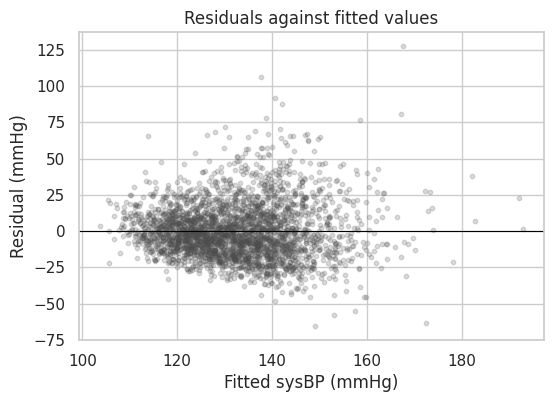

In [460]:
fitted, resid = ols_full.fittedvalues, ols_full.resid
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(fitted, resid, alpha=0.2, s=10, color="0.3")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Residuals against fitted values")
ax.set_xlabel("Fitted sysBP (mmHg)")
ax.set_ylabel("Residual (mmHg)")
plt.show()

**🔎 What each line does**

- `fitted, resid = `  →  the model's predictions on training rows and the errors
- `ax.scatter(fitted, resid`  →  one dot per person
- `ax.axhline(0`  →  a reference line at zero error
- `ax.set_title`  →  title
- `ax.set_xlabel`  →  x label
- `ax.set_ylabel`  →  y label

**👀 What you should see:** a cloud that fans out to the right: larger errors at higher fitted values.

### ▶️ SEE · A Q-Q plot

If the residuals were perfectly normal, the dots would lie on the line.

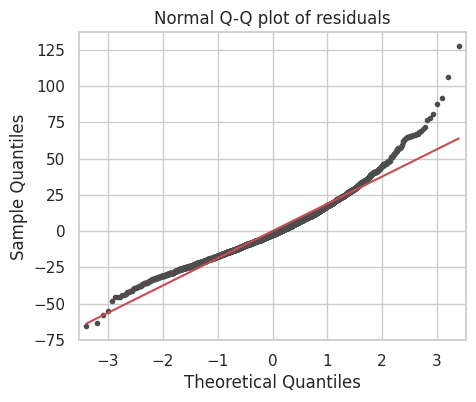

In [461]:
fig, ax = plt.subplots(figsize=(5, 4))
sm.qqplot(resid, line="s", ax=ax, markersize=3, markerfacecolor="0.3", markeredgecolor="0.3")
ax.set_title("Normal Q-Q plot of residuals")
plt.show()

**🔎 What each line does**

- `sm.qqplot(resid, line="s"`  →  plots residual quantiles against normal quantiles with a reference line
- `markersize=3`  →  small dots
- `ax.set_title`  →  title

**👀 What you should see:** dots bend upward away from the line at the right: a heavy upper tail.

### ▶️ SEE · A test for constant variance

The Breusch-Pagan test: a small p-value means the spread is not constant.

In [462]:
bp_p = het_breuschpagan(ols_full.resid, ols_full.model.exog)[1]
print(f"Breusch-Pagan p = {bp_p:.1e}")

Breusch-Pagan p = 6.0e-29


**👀 What you should see:** a very small p-value.

### ▶️ SEE · Influential rows

Cook's distance: rows above 4/n are worth a look (not worth deleting automatically).

In [463]:
cooks = ols_full.get_influence().cooks_distance[0]
print(int((cooks > 4 / len(train_fe)).sum()), "of", len(train_fe))

152 of 2968


**👀 What you should see:** 152 of 2968 rows.

### ▶️ SEE · A robust response

HC3 standard errors tolerate unequal spread; the coefficient stays the same, the interval changes slightly.

In [464]:
robust = smf.ols(formula_sbp, data=train_fe).fit(cov_type="HC3")
print(ols_full.conf_int().loc["age_dec"].round(2).tolist(), robust.conf_int().loc["age_dec"].round(2).tolist())

[7.92, 9.66] [7.87, 9.71]


**👀 What you should see:** the ordinary and robust intervals are similar for age.

Responses to a violation: use **robust standard errors**, **transform the outcome** (log), or use a more flexible model (Notebook 4). Do **not** delete influential rows just because they are influential; at most compare with and without them.

### ✏️ TRY · Exercise 3.8 · Model log(sysBP) instead

Fit the same model with `np.log(sysBP)` as the outcome (`formula_log`) as `ols_log`. Store the skewness of the residuals of both models in `resid_skew_raw` and `resid_skew_log`, and `age_pct_per_decade` = `100 * (np.exp(coef) - 1)` for the `age_dec` coefficient of the log model (percentage change per decade).

**Result variable(s):** `resid_skew_raw`, `resid_skew_log`, `age_pct_per_decade`

In [465]:
# [Exercise 3.8]
formula_log = formula_sbp.replace("sysBP ~", "np.log(sysBP) ~")
ols_log = smf.ols(formula_log, data=train_fe).fit()              # smf.ols(formula_log, data=train_fe).fit()
resid_skew_raw = pd.Series(ols_full.resid).skew()       # pd.Series(ols_full.resid).skew()
resid_skew_log = pd.Series(ols_log.resid).skew()        # pd.Series(ols_log.resid).skew()
age_pct_per_decade =100* (np.exp(ols_log.params["age_dec"])-1)    # 100 * (np.exp(ols_log.params["age_dec"]) - 1)
print(resid_skew_raw, resid_skew_log, age_pct_per_decade)

0.8809337114730771 0.35842180454111955 6.48531464440405


In [466]:
check("3.8")   # 🎯 run this cell to check your answer

✅ `resid_skew_raw`: correct!
✅ `resid_skew_log`: correct!
✅ `age_pct_per_decade`: correct!


### 🔍 ANALYZE · Question 3.7 · What do the residual plots show?

Describe the residual plot and the Q-Q plot, say which assumption is violated, and explain what that means for the intervals.

*Write your answer inside the quotes below (2–5 sentences). Your instructor reads it.*

In [467]:
# [Question 3.7]
answer_3_7 = """The residuals-versus-fitted plot shows that the residuals are generally scattered around zero, but their spread increases slightly at higher fitted values, suggesting possible heteroscedasticity (unequal variance).
The Q-Q plot also shows departures from the straight line, particularly in the upper tail, indicating that the residuals are not normally distributed.
 Therefore, the constant variance and normality assumptions may be violated. This means that the usual confidence intervals and p-values may be unreliable, so robust standard errors or other appropriate methods should be considered.

"""

In [468]:
check("Q3.7")   # 🎯 run this cell to check your answer

📝 answer saved (82 words). Your teacher will read it.


### ✅ CHECK · Knowledge check 3.7

Residuals fan out as fitted values increase. Which assumption is violated?

- **A.** Independence
- **B.** Constant variance (homoscedasticity)
- **C.** No missing values
- **D.** Linearity of the intercept

In [469]:
# [Knowledge check 3.7]
kc_3_7 = "B"   # type "A", "B", "C" or "D"

In [470]:
check("K3.7")   # 🎯 run this cell to check your answer

✅ `kc_3_7`: correct!


---
## Part 8 · Logistic regression for TenYearCHD
*About 40 min · Research question(s): RQ8, RQ13*

### 📘 LEARN · From coefficients to odds ratios

For a yes/no outcome, **logistic regression** models the *log-odds* of the outcome. Exponentiating a coefficient (`np.exp`) gives an **odds ratio (OR)** for a one-unit difference in that predictor, adjusted for the others:
OR = 1 no association; OR above 1 higher odds; OR below 1 lower odds. Report the **95% interval**.
The OR is not a risk ratio: with a common outcome (15%) it exaggerates the relative risk. This is an **explanatory** model fitted on training rows; it is not a validated risk score (prediction is judged in Notebook 5).
We include `sbp_20` but not `diaBP` (they overlap) and `cigs_10` but not `currentSmoker` (cigarettes per day is already 0 for non-smokers).

**📖 New words**

- **log-odds**: the natural logarithm of the odds
- **odds ratio**: factor by which the odds change per one-unit difference
- **pseudo R squared**: a rough fit measure for logistic models

### ▶️ SEE · Fit the model

`smf.logit` works like `smf.ols` but for a 0/1 outcome. `disp=0` hides the long fitting log.

In [471]:
formula_chd = ("TenYearCHD ~ male + age_dec + C(education) + cigs_10 + BPMeds + prevalentStroke "
               "+ prevalentHyp + diabetes + chol_40 + sbp_20 + bmi_5 + hr_10 + glu_20 + glucose_missing")
logit_full = smf.logit(formula_chd, data=train_fe).fit(disp=0)
print(len(logit_full.params), "coefficients fitted")

17 coefficients fitted


**🔎 What each line does**

- `formula_chd = (`  →  outcome ~ predictors, as before
- `sbp_20`  →  blood pressure in steps of 20 mmHg (predictor in this model)
- `smf.logit(formula_chd`  →  describes a logistic model
- `.fit(disp=0)`  →  calculates it quietly

**👀 What you should see:** `17 coefficients fitted`.

### ▶️ SEE · Odds ratios with intervals

We exponentiate the coefficients and the ends of their intervals.

In [472]:
odds = pd.DataFrame({"OR": np.exp(logit_full.params), "ci_low": np.exp(logit_full.conf_int()[0]),
                     "ci_high": np.exp(logit_full.conf_int()[1]), "p": logit_full.pvalues})
print(odds.round(3))

                        OR  ci_low  ci_high      p
Intercept            0.086   0.067    0.111  0.000
C(education)[T.2.0]  0.866   0.661    1.134  0.296
C(education)[T.3.0]  0.980   0.706    1.359  0.903
C(education)[T.4.0]  1.058   0.742    1.508  0.755
male                 1.644   1.298    2.084  0.000
age_dec              1.846   1.598    2.132  0.000
cigs_10              1.257   1.148    1.378  0.000
BPMeds               1.427   0.866    2.353  0.163
prevalentStroke      3.296   1.154    9.412  0.026
prevalentHyp         1.170   0.868    1.578  0.303
diabetes             1.109   0.566    2.174  0.763
chol_40              1.070   0.974    1.176  0.158
sbp_20               1.318   1.157    1.500  0.000
bmi_5                1.028   0.900    1.173  0.687
hr_10                0.963   0.879    1.055  0.423
glu_20               1.155   1.043    1.280  0.006
glucose_missing      0.965   0.662    1.407  0.853


**👀 What you should see:** age_dec has an OR of about 1.85; sbp_20 and male are above 1 too.

### ✏️ TRY · Exercise 3.9 · An odds ratio for age

From `logit_full`, store the odds ratio per decade of age in `or_age_dec` and its interval limits in `or_age_low` and `or_age_high` (exponentiate the coefficient and the limits from `conf_int().loc['age_dec']`).

**Result variable(s):** `or_age_dec`, `or_age_low`, `or_age_high`

In [473]:
# [Exercise 3.9]
or_age_dec =np.exp(logit_full.params["age_dec"])    # np.exp(logit_full.params["age_dec"])
or_age_low =np.exp(logit_full.conf_int().loc["age_dec"][0])    # np.exp(logit_full.conf_int().loc["age_dec"][0])
or_age_high = np.exp(logit_full.conf_int().loc["age_dec"][1])    # np.exp(logit_full.conf_int().loc["age_dec"][1])
print(or_age_dec, or_age_low, or_age_high)

1.8461092916974207 1.5984457059231172 2.1321459366824924


In [474]:
check("3.9")   # 🎯 run this cell to check your answer

✅ `or_age_dec`: correct!
✅ `or_age_low`: correct!
✅ `or_age_high`: correct!


### ▶️ SEE · Unadjusted odds ratio for cigarettes

A logistic model with a single predictor.

In [475]:
logit_unadj = smf.logit("TenYearCHD ~ cigs_10", data=train_fe).fit(disp=0)
print(round(np.exp(logit_unadj.params["cigs_10"]), 2))

1.14


**👀 What you should see:** about `1.14` per 10 cigarettes a day.

### ✏️ TRY · Exercise 3.10 · Unadjusted versus adjusted smoking association

Store the unadjusted OR for `cigs_10` in `or_cigs_unadj` (from a model with `cigs_10` alone) and the adjusted OR from `logit_full` in `or_cigs_adj`.

**Result variable(s):** `or_cigs_unadj`, `or_cigs_adj`

In [476]:
# [Exercise 3.10]
logit_unadj = smf.logit("TenYearCHD ~ cigs_10", data=train_fe).fit(disp=0)
or_cigs_unadj = np.exp(logit_unadj.params["cigs_10"])    # np.exp(logit_unadj.params["cigs_10"])
or_cigs_adj = np.exp(logit_full.params["cigs_10"])     # np.exp(logit_full.params["cigs_10"])
print(or_cigs_unadj, or_cigs_adj)

1.142895568023037 1.2574304146611586


In [477]:
check("3.10")   # 🎯 run this cell to check your answer

✅ `or_cigs_unadj`: correct!
✅ `or_cigs_adj`: correct!


### 💬 INTERPRET · Question 3.8 · Why did adjustment strengthen the smoking association?

The adjusted OR for cigarettes per day (1.26) is larger than the unadjusted OR (1.14). Using Notebook 2 (smokers are younger), explain why, and say what 'OR = 1.26 per 10 cigarettes a day' means and does not mean.

*Write your answer inside the quotes below (2–5 sentences). Your instructor reads it.*

In [478]:
# [Question 3.8]
answer_3_8 = """Smokers are younger, according to Notebook 2, and younger age is associated with a lower risk of coronary heart disease (CHD).
Therefore, age negatively confounds the crude smoking association, making the unadjusted OR (1.14) smaller; adjusting for age increases it to 1.26.
 An OR of 1.26 per 10 cigarettes per day means that each additional 10 cigarettes smoked daily is associated with 26% higher odds of CHD, holding other variables constant.
 It does not mean a 26% increase in the probability of CHD or prove that smoking causes a 26% increase in risk.

"""

In [479]:
check("Q3.8")   # 🎯 run this cell to check your answer

📝 answer saved (93 words). Your teacher will read it.


### 💬 INTERPRET · Question 3.9 · Reading the odds-ratio table

Pick one predictor clearly associated with CHD and one whose interval includes 1. Interpret both, and say what an interval that includes 1 does and does not tell you.

*Write your answer inside the quotes below (2–5 sentences). Your instructor reads it.*

In [480]:
# [Question 3.9]
answer_3_9 = """cigs_10 is significantly associated with CHD (OR = 1.257, 95% CI: 1.148–1.378), meaning that every additional 10 cigarettes smoked per day is associated with approximately 25.7% higher odds of CHD, holding other variables constant.
 In contrast, BPMeds (OR = 1.427, 95% CI: 0.866–2.353) is not statistically significant because its confidence interval includes 1. An interval that includes 1 means there is insufficient evidence of an association at the 5% significance level, but it does not prove that no association exists.

"""

In [481]:
check("Q3.9")   # 🎯 run this cell to check your answer

📝 answer saved (80 words). Your teacher will read it.


### ✅ CHECK · Knowledge check 3.8

In the CHD model `age_dec` has OR = 1.85. Which statement is best?

- **A.** Each extra decade of age adds 85% to the risk of CHD
- **B.** Holding other predictors fixed, the odds of CHD are about 1.85 times higher per decade of age
- **C.** 85% of older people develop CHD
- **D.** Age causes CHD with probability 1.85

In [482]:
# [Knowledge check 3.8]
kc_3_8 = "B"   # type "A", "B", "C" or "D"

In [483]:
check("K3.8")   # 🎯 run this cell to check your answer

✅ `kc_3_8`: correct!


---
## Part 9 · Statistical versus practical importance
*About 25 min · Research question(s): RQ9, RQ11*

### 📘 LEARN · Which predictors really matter?

A small p-value says the data are hard to reconcile with *zero* association. It does not say the predictor is *useful*. A simple measure of usefulness is the **drop in R squared** when a predictor is removed from the model (its unique contribution, given the others).

### ▶️ SEE · Step 1: remove one predictor and refit

We delete `bmi_5` from the formula text and refit.

In [484]:
without_bmi = smf.ols(formula_sbp.replace(" + bmi_5", ""), data=train_fe).fit()
print(round(ols_full.rsquared - without_bmi.rsquared, 4))

0.0574


**👀 What you should see:** about `0.06`: BMI uniquely explains about 6% of sysBP variation.

### ▶️ SEE · Step 2: repeat for every predictor

A loop does Step 1 for each term and collects the drops in a table.

In [485]:
terms = ["male", "age_dec", "C(education)", "currentSmoker", "cigs_10", "diabetes", "prevalentStroke",
         "chol_40", "bmi_5", "hr_10", "glu_20", "glucose_missing"]
rows = []
for term in terms:
    reduced = formula_sbp.replace(" + " + term, "").replace(term + " + ", "")
    r2_reduced = smf.ols(reduced, data=train_fe).fit().rsquared
    rows.append({"term": term, "drop_in_R2": ols_full.rsquared - r2_reduced})
contribution = pd.DataFrame(rows).set_index("term").sort_values("drop_in_R2", ascending=False)

**🔎 What each line does**

- `terms = [`  →  the formula terms to test
- `rows = []`  →  an empty list for the results
- `for term in terms:`  →  repeat for each term
- `reduced = formula_sbp.replace`  →  the formula with this term removed
- `r2_reduced = smf.ols(`  →  fit the reduced model and take its R squared
- `rows.append(`  →  store the drop in R squared
- `contribution = pd.DataFrame(rows)`  →  make a table sorted from biggest drop to smallest

**👀 What you should see:** nothing printed.

### ▶️ SEE · The table

In [486]:
print(contribution.round(4))

                 drop_in_R2
term                       
age_dec           9.590e-02
bmi_5             5.740e-02
hr_10             1.860e-02
chol_40           4.800e-03
glu_20            3.200e-03
prevalentStroke   1.900e-03
C(education)      1.200e-03
male              7.000e-04
currentSmoker     4.000e-04
cigs_10           2.000e-04
glucose_missing   1.000e-04
diabetes          0.000e+00


**👀 What you should see:** age and BMI have the largest drops; glucose is very small.

### ✏️ TRY · Exercise 3.11 · Unique contribution of BMI and glucose

Store `delta_r2_bmi` and `delta_r2_glucose`: R squared of `ols_full` minus R squared of the model without `bmi_5` (respectively `glu_20`). Build the reduced formula with `formula_sbp.replace(" + bmi_5", "")`.

**Result variable(s):** `delta_r2_bmi`, `delta_r2_glucose`

In [487]:
# [Exercise 3.11]
without_bmi = smf.ols(formula_sbp.replace("+ bmi_5", ""), data=train_fe).fit()     # smf.ols(formula_sbp.replace(" + bmi_5", ""), data=train_fe).fit()
without_glu = smf.ols(formula_sbp.replace("+ glu_20", ""), data=train_fe).fit()     # smf.ols(formula_sbp.replace(" + glu_20", ""), data=train_fe).fit()
delta_r2_bmi = ols_full.rsquared- without_bmi.rsquared   # ols_full.rsquared - without_bmi.rsquared
delta_r2_glucose = ols_full.rsquared- without_glu.rsquared
print(delta_r2_bmi, delta_r2_glucose)

0.05738239083015917 0.0031717183913229086


In [488]:
check("3.11")   # 🎯 run this cell to check your answer

✅ `delta_r2_bmi`: correct!
✅ `delta_r2_glucose`: correct!


### 💬 INTERPRET · Question 3.10 · Which predictors contribute most?

Using the contribution table and the coefficients, which predictors contribute most to explaining sysBP? Give one example where statistical significance and practical contribution disagree.

*Write your answer inside the quotes below (2–5 sentences). Your instructor reads it.*

In [489]:
# [Question 3.10]
answer_3_10 = """Age (age_dec) contributes the most to explaining systolic blood pressure, with a drop in R² of 0.0959, followed by BMI (`bmi_5`) at 0.0574 and heart rate (`hr_10`) at 0.0186. This suggests that age and BMI have the greatest unique explanatory contributions among the predictors.
For example, cigs_10 may be statistically significant in the coefficient table but has a very small drop in R² of 0.0002, showing that statistical significance does not necessarily mean substantial practical contribution.

"""

In [490]:
check("Q3.10")   # 🎯 run this cell to check your answer

📝 answer saved (76 words). Your teacher will read it.


### ✅ CHECK · Knowledge check 3.9

A predictor has p < 0.001 but its removal changes R squared by 0.004. The best description is:

- **A.** Statistically detectable but practically minor
- **B.** Practically essential
- **C.** Not associated with the outcome
- **D.** A proxy for the target

In [491]:
# [Knowledge check 3.9]
kc_3_9 = "A"   # type "A", "B", "C" or "D"

In [492]:
check("K3.9")   # 🎯 run this cell to check your answer

✅ `kc_3_9`: correct!


---
## Part 10 · Putting it together
*About 20 min · Research question(s): RQ7, RQ8, RQ10, RQ11, RQ13*

### 💬 INTERPRET · Question 3.11 · What can the two models tell us?

In one paragraph (about 6 sentences): (1) how well can sysBP be estimated, judged on validation rows? (2) which predictors matter most? (3) what did the logistic model say about age, smoking and blood pressure? (4) name two reasons not to treat either model as causal or clinical.

*Write your answer inside the quotes below (2–5 sentences). Your instructor reads it.*

In [493]:
# [Question 3.11]
answer_3_11 = """The sysBP model identifies meaningful predictors of systolic blood pressure, although its exact predictive accuracy on validation rows must be assessed using the validation performance metrics.
Age contributed most to explaining sysBP (drop in R² = 0.0959), followed by BMI (0.0574) and heart rate (0.0186).
 The CHD logistic model showed that a 10-year increase in age was associated with 84.6% higher odds of CHD, while every additional 10 cigarettes smoked daily was associated with 25.7% higher odds.
 Similarly, a 20 mmHg increase in systolic blood pressure was associated with 31.8% higher odds of CHD.
 Neither model establishes causation because the data are observational and may be affected by confounding, and neither should be adopted for clinical decisions without independent validation.

"""

In [494]:
check("Q3.11")   # 🎯 run this cell to check your answer

📝 answer saved (120 words). Your teacher will read it.


### 💭 REFLECT · Question 3.12 · One decision, one consequence

Name one analysis decision from this notebook and describe how you would test whether it changed the conclusions.

*Write your answer inside the quotes below (2–5 sentences). Your instructor reads it.*

In [495]:
# [Question 3.12]
answer_3_12 = """One important decision was excluding diastolic blood pressure (diaBP) from the systolic blood pressure (sysBP) prediction model because the two measurements are closely related.
 I would test this decision by fitting a second model that includes diaBP and comparing the validation R², RMSE and MAE with those of the original model.
  I would also compare the predictor coefficients to see whether their size, direction or statistical significance changes.
  If prediction improves substantially, it would show that excluding diaBP reduced predictive accuracy, although its suitability would still depend on whether it is available at the intended prediction time.

"""

In [496]:
check("Q3.12")   # 🎯 run this cell to check your answer

📝 answer saved (97 words). Your teacher will read it.


### 🔬 RESEARCH · Task 3.1 · Complete-case versus imputed regression

Refit the sysBP model using **complete cases only** (drop training rows with a gap in the variables used; `glucose_missing` is then constant, so drop that term). Compare the `age_dec`, `bmi_5` and `glu_20` coefficients with `ols_full`. Do conclusions change? State what the comparison cannot tell you.

Use the code cell for your analysis and summarise what you found, and what you could *not* conclude, in `research_3_1_summary`.

In [497]:
# [Research 3.1]

# Variables required for the complete-case analysis
required_vars = [
    "sysBP", "education", "male", "age_dec",
    "currentSmoker", "cigs_10", "diabetes",
    "prevalentStroke", "chol_40", "bmi_5",
    "hr_10", "glu_20"
]

# Retain only observations with complete data
cc_data = train_fe.dropna(subset=required_vars).copy()

# Fit complete-case regression
formula_cc = """
sysBP ~ C(education) + male + age_dec + currentSmoker
+ cigs_10 + diabetes + prevalentStroke + chol_40
+ bmi_5 + hr_10 + glu_20
"""

ols_cc = smf.ols(formula=formula_cc, data=cc_data).fit()

# Compare the three requested coefficients
terms = ["age_dec", "bmi_5", "glu_20"]

comparison = pd.DataFrame({
    "ols_full": ols_full.params[terms],
    "complete_case": ols_cc.params[terms]
})

comparison["difference"] = (
    comparison["complete_case"] - comparison["ols_full"]
)

comparison["full_p"] = ols_full.pvalues[terms]
comparison["complete_case_p"] = ols_cc.pvalues[terms]

print("Complete-case sample size:", len(cc_data))
print("\nCoefficient comparison:")
print(comparison.round(4))


  # TODO: your independent analysis goes here


research_3_1_summary = """  The complete-case regression included 2,968 observations and produced almost identical results to the original imputed regression.
The age coefficient changed from 8.791 to 8.790, BMI changed from 6.712 to 6.708, and glucose changed from 1.389 to 1.398.
All three predictors remained statistically significant (p < 0.001), so the conclusions did not change meaningfully.
 However, this comparison cannot establish which missing-data method is more accurate, determine the true values of missing observations, or rule out selection bias from excluding incomplete cases.
  It also cannot establish causal relationships between the predictors and systolic blood pressure.

"""

Complete-case sample size: 2968

Coefficient comparison:
         ols_full  complete_case  difference     full_p  complete_case_p
age_dec     8.791          8.790      -0.001  0.000e+00        0.000e+00
bmi_5       6.712          6.708      -0.004  0.000e+00        0.000e+00
glu_20      1.389          1.398       0.009  3.000e-04        3.000e-04


In [498]:
check("R3.1")   # 🎯 run this cell to check your answer

📝 answer saved (93 words). Your teacher will read it.


---
### 📊 Your progress
Run this cell to see how many checks you have passed so far.

In [499]:
progress(3)

Notebook 3 progress
  Exercises passed:           11 of 11
  Knowledge checks correct:   9 of 9
  Written answers completed:  13 of 13  (your teacher reads these)
🎉 Everything is complete. Save your notebook with your name in the filename.
  (Feedback only. Your instructor's marking is separate.)


---
### 📝 How this notebook is assessed
Your work is judged on **understanding**, not on matching a model answer line by line. Different correct approaches earn full credit.

| Criterion | Marks | Share |
|---|---|---|
| Correctness of analysis | 34.5 | 33% |
| Choice of statistical method | 1.5 | 1% |
| Interpretation | 33 | 31% |
| Code quality and reproducibility | 0 | 0% |
| Critical thinking and scientific reasoning | 37 | 35% |
| **Total** | **106.0** | |

The 🎯 checks give you feedback on the *result* you produce; the official marks come from your instructor, who also reads your written answers and research tasks.

### ✅ Before you submit
1. *Runtime → Restart session and run all* (or *Kernel → Restart & Run All*) finishes without errors.
2. Every `# TODO` is replaced and every `answer_...` variable is filled in.
3. Figures have a title, labelled axes and a legend when needed.
4. Save the notebook with your name in the filename.